In [2]:
import numpy as np
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("credit_risk_dataset.csv")

In [5]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [7]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [8]:
len(df["loan_status"].unique())

2

In [9]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

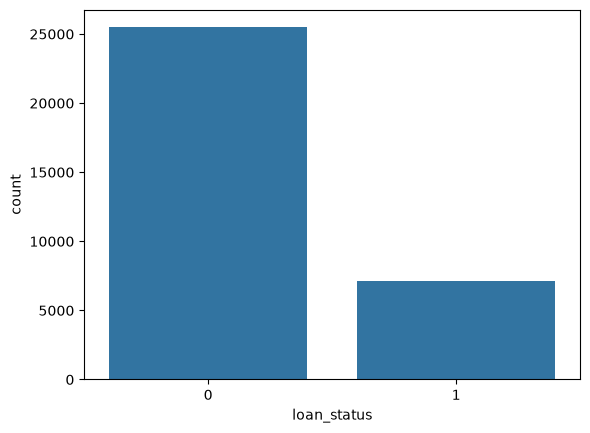

In [10]:
sns.countplot(x='loan_status',data=df)

In [11]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [12]:
numerical_cols = df.select_dtypes(include=["int64","float64"]).columns
(numerical_cols.tolist())

['person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'loan_int_rate',
 'loan_status',
 'loan_percent_income',
 'cb_person_cred_hist_length']

In [13]:
df.describe(include="object")

C:\Users\DELL\AppData\Local\Temp\ipykernel_23228\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


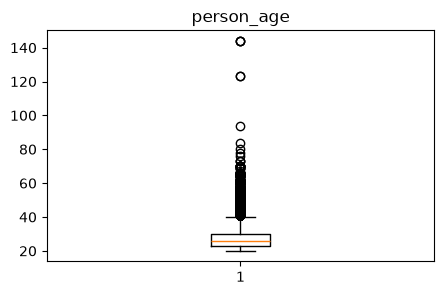

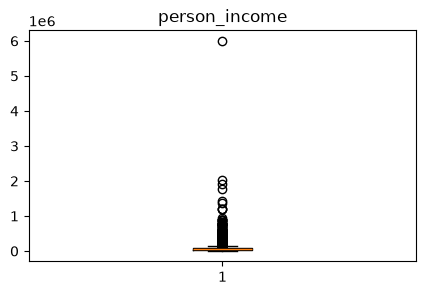

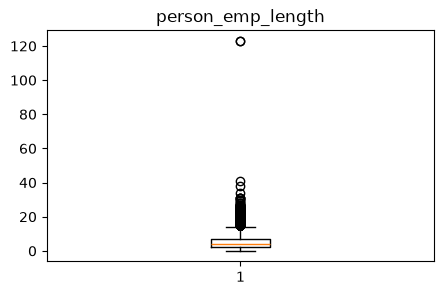

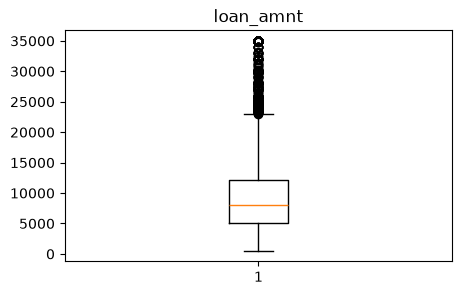

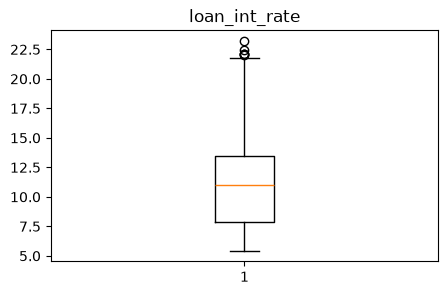

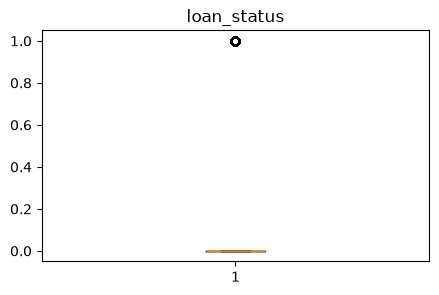

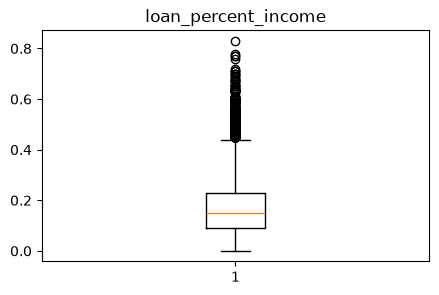

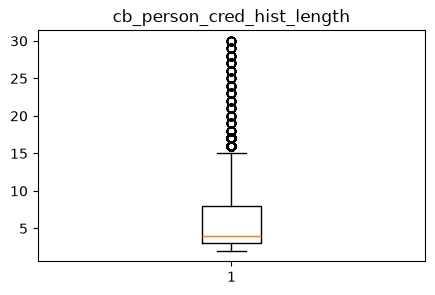

In [14]:
for column in numerical_cols:
    plt.figure(figsize=(5,3))
    plt.boxplot(df[column].dropna())
    plt.title(column)
    plt.show()

In [15]:
#counting columns with age greater than 140

(df["person_age"]>100).sum()

np.int64(5)

In [16]:
(df["person_emp_length"]>40).sum()

np.int64(3)

In [17]:
num_cols = df.select_dtypes(include=["int64","float64"])
corr_matrix = num_cols.corr()

<Axes: >

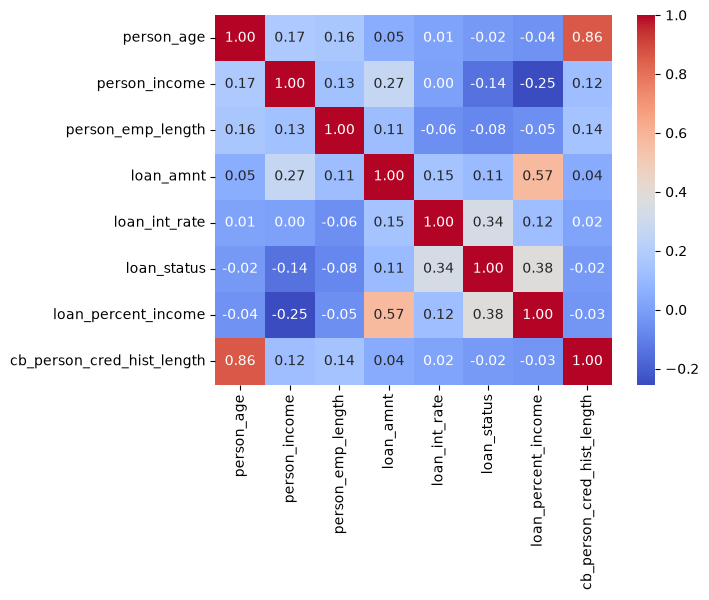

In [18]:
sns.heatmap(corr_matrix,
            annot = True,
            fmt=".2f",
            cmap = "coolwarm"
)

In [19]:
corr_matrix["loan_status"].sort_values(ascending=False)

loan_status                   1.000000
loan_percent_income           0.379366
loan_int_rate                 0.335133
loan_amnt                     0.105376
cb_person_cred_hist_length   -0.015529
person_age                   -0.021629
person_emp_length            -0.082489
person_income                -0.144449
Name: loan_status, dtype: float64

In [20]:
df_copy = df.copy()
df.shape[0]

32581

In [21]:
#removing duplicate rows 

df_copy.drop_duplicates(inplace=True)
df_copy.shape[0]

32416

In [22]:
#removing rows with age less than 18 or greater than 100
df_copy = df_copy[df_copy["person_age"] >= 18]

df_copy = df_copy[df_copy["person_age"] <=100]

df_copy.shape[0]

#remove rows with emp_length greater than the person age
df_copy = df_copy[df_copy["person_emp_length"] <= df_copy["person_age"]]

df_copy.shape[0]

df = df_copy

df.shape[0]



31522

In [23]:
X = df_copy.drop("loan_status",axis=1)
y = df_copy["loan_status"]

In [24]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [25]:
# handling class imbalance 
neg,pos = np.bincount(y_train)
scale_weights = neg/pos

In [26]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 31522 entries, 1 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  31522 non-null  int64  
 1   person_income               31522 non-null  int64  
 2   person_home_ownership       31522 non-null  str    
 3   person_emp_length           31522 non-null  float64
 4   loan_intent                 31522 non-null  str    
 5   loan_grade                  31522 non-null  str    
 6   loan_amnt                   31522 non-null  int64  
 7   loan_int_rate               28495 non-null  float64
 8   loan_status                 31522 non-null  int64  
 9   loan_percent_income         31522 non-null  float64
 10  cb_person_default_on_file   31522 non-null  str    
 11  cb_person_cred_hist_length  31522 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.1 MB


In [27]:
num_cols = df.select_dtypes(include = ["int64","float64"]).columns.tolist()

# but we need to remove loan_status as we dont need loan_status(output column) now 

num_cols = ['person_age','person_income','person_emp_length','loan_amnt','loan_int_rate','loan_percent_income','cb_person_cred_hist_length']

cat_cols = ["person_home_ownership","loan_intent","loan_grade", "cb_person_default_on_file"]

In [28]:
df["cb_person_default_on_file"].unique()

<StringArray>
['N', 'Y']
Length: 2, dtype: str

In [29]:
#Logistic regression
#impute + scale numeric + one hot encoding

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder 


# preprocessing for numerical data
num_transformer = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

# Preprocessing for categorical data
cat_transformer = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

processor_lr = ColumnTransformer([
    ("num",num_transformer,num_cols),
    ("cat",cat_transformer,cat_cols)
])
# here ColumnTransformer decides that what data is numerical or categorical and sends them accordingly to the transformer


In [30]:
#XGBoost pipeline
#for preprocessing no scaling is required as its not needed for tree models

# preprocessing for numerical data
num_transformer = Pipeline([
    ("imputer",SimpleImputer(strategy="median"))
])

# Preprocessing for categorical data
cat_transformer = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

processor_xg = ColumnTransformer([
    ("num",num_transformer,num_cols),
    ("cat",cat_transformer,cat_cols)
])



In [31]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits = 5,random_state=42,shuffle=True)

scoring = {"roc_auc":"roc_auc","accuracy":"accuracy","precision":"precision","recall":"recall","f1":"f1"}

In [32]:
#defining the L.R. model
from sklearn.linear_model import LogisticRegression

lr_cv_pipeline = Pipeline([
    ("preprocessor",processor_lr),
    ("classifier",LogisticRegression(max_iter=1000,random_state=42,class_weight="balanced"))
])

In [33]:
#Defining the XGBoost model 
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([
    ("preprocessor",processor_xg),
    ("classifier",XGBClassifier(
        n_estimators=300,max_depth=5,learning_rate=0.1,scale_pos_weight=scale_weights,random_state=42
    ))
])

In [34]:
from sklearn.model_selection import cross_validate

In [35]:
for cv_name,pipe in [("Logistic Regression",lr_cv_pipeline),
                     ("XGBoost",xgb_cv_pipeline)] :
    
    cv_results = cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    
    
    print(cv_name)
    
    print(f"ROC-AUC for : {cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
    print(f"Precision : {cv_results['test_precision'].mean()}")
    print(f"Recall : {cv_results['test_recall'].mean()}")
    print(f"F1 : {cv_results['test_f1'].mean()}")    
    
    

Logistic Regression
ROC-AUC for : 0.8705112830525306
Accuracy : 0.8115949542892269
Precision : 0.5448226008889892
Recall : 0.7781450872359963
F1 : 0.6408013995933108
XGBoost
ROC-AUC for : 0.9471668355515135
Accuracy : 0.9182296642215565
Precision : 0.8195330117664359
Recall : 0.7974288337924702
F1 : 0.8081410985599564


In [36]:
cv_results

{'fit_time': array([0.89664221, 0.95191979, 0.99875593, 0.84111929, 0.82162285]),
 'score_time': array([0.06912684, 0.07463288, 0.06573176, 0.0747385 , 0.07825685]),
 'test_roc_auc': array([0.94953303, 0.93862031, 0.94699977, 0.95139258, 0.94928849]),
 'test_accuracy': array([0.91831879, 0.92069786, 0.91869919, 0.92028554, 0.91314694]),
 'test_precision': array([0.81964117, 0.84278607, 0.82119205, 0.8189415 , 0.79510426]),
 'test_recall': array([0.79706152, 0.77777778, 0.79706152, 0.80991736, 0.80532599]),
 'test_f1': array([0.80819367, 0.80897803, 0.80894688, 0.81440443, 0.80018248])}

In [37]:
lr_baseline_model = Pipeline([
    ("preprocessor",processor_lr),
    ("Classifier",LogisticRegression(class_weight = "balanced"))
])

lr_baseline_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('Classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [38]:
xg_model = Pipeline([
    ("preprocessor",processor_xg),
    ("classifier",XGBClassifier(n_estimators=300,max_depth=5,learning_rate=0.1,scale_pos_weight=scale_weights,random_state=42))
])

xg_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [39]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,precision_recall_curve


def evaluate_model(model_name,model,X_test,y_test,threshold=None):
    y_pred_prob = model.predict_proba(X_test)[:,1]
    
    if threshold :
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(X_test)
    
    #metrics  
    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    recall = recall_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    
    print(f"accuracy : {accuracy:.2f}")
    print(f"precision : {precision:.2f}")
    print(f"recall : {recall:.2f}")
    print(f"f1_score : {f1:.2f}")
        
    cm = confusion_matrix(y_test,y_pred)
    class_report = classification_report(y_test,y_pred)
    print(class_report)
    
    sns.heatmap(cm,annot=True,fmt="d")
    plt.title(f"{model_name} confusion matrix")
    plt.ylabel("actual values")
    plt.xlabel("Predicted values")
    plt.show()
    
    
    #plotting ROC-AUC curve
    precisions,recalls,threshold = precision_recall_curve(y_test,y_pred)
    plt.plot(recalls,precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

accuracy : 0.82
precision : 0.56
recall : 0.79
f1_score : 0.65
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



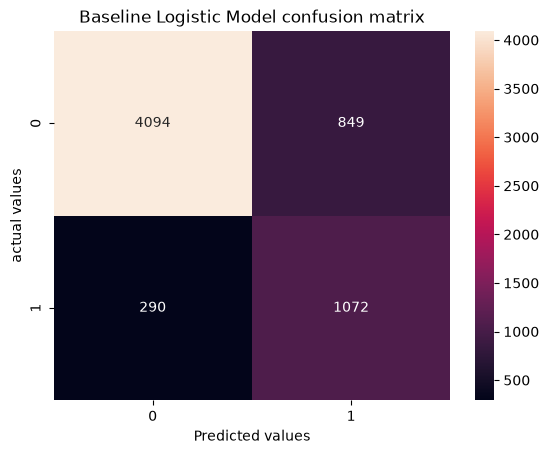

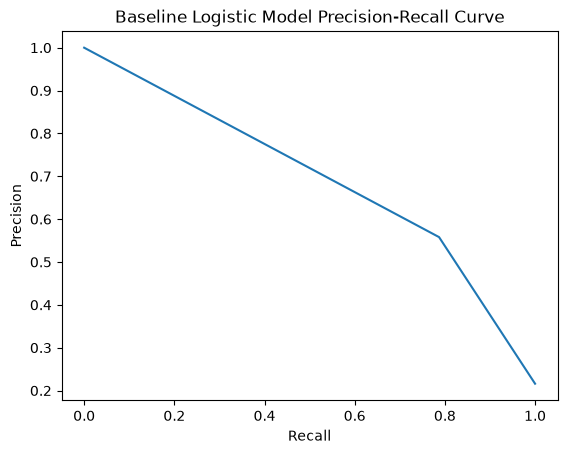

In [40]:
evaluate_model("Baseline Logistic Model",lr_baseline_model,X_test,y_test)

In [41]:
from sklearn.model_selection import RandomizedSearchCV

from scipy.stats import uniform,randint


param_grid = {
    "classifier__n_estimators" : randint(150,600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01,0.5),
    "classifier__subsample" : uniform(0.4,0.6),
    "classifier__colsample_bytree" : uniform(0.4,0.6),
    "classifier__min_child_weight" : randint(1,10),
    "classifier__gamma" : uniform(0,5)
}

In [42]:
random_search = RandomizedSearchCV(
    estimator=xg_model,param_distributions=param_grid,n_iter=150,cv=cv,scoring="average_precision",n_jobs=-1,verbose=1
)

random_search.fit(X_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....00167C859DF10>, 'classifier__gamma': <scipy.stats....00167C85AAAD0>, 'classifier__learning_rate': <scipy.stats....00167C84AD3D0>, 'classifier__max_depth': <scipy.stats....00167C84B6590>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

In [ ]:
print("Best parameters: ",random_search.best_params_)
print("Best CV F1 Score: ",random_search.best_score_)

best_sgb = random_search.best_estimator_

y_pred = best_sgb.predict(X_test)

Best parameters:  {'classifier__colsample_bytree': np.float64(0.6062321432664501), 'classifier__gamma': np.float64(0.4225665168512954), 'classifier__learning_rate': np.float64(0.1701178424439187), 'classifier__max_depth': 6, 'classifier__min_child_weight': 9, 'classifier__n_estimators': 216, 'classifier__subsample': np.float64(0.9984080419822541)}
Best CV F1 Score:  0.9028424947852838


accuracy : 0.92
precision : 0.82
recall : 0.81
f1_score : 0.81
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



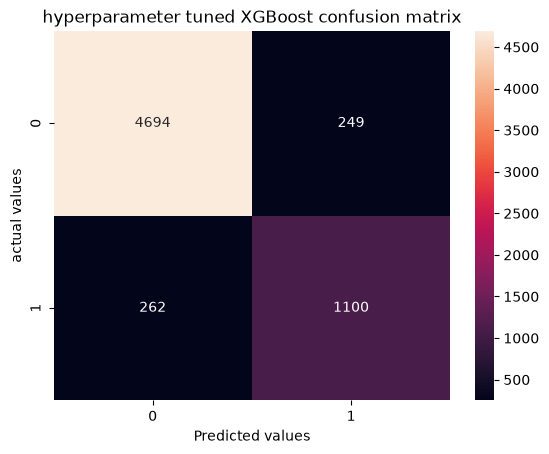

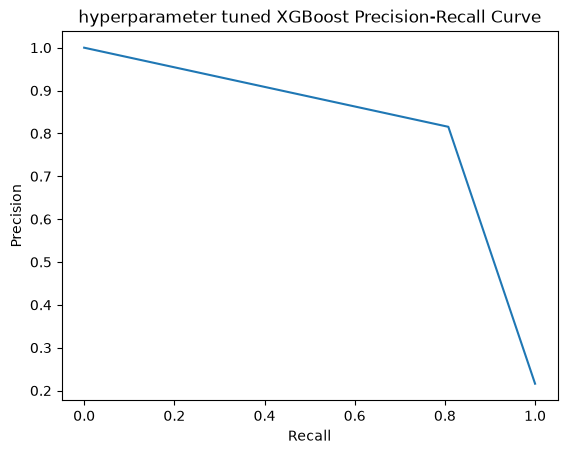

In [44]:
evaluate_model("hyperparameter tuned XGBoost",best_sgb,X_test,y_test)

accuracy : 0.92
precision : 0.82
recall : 0.81
f1_score : 0.81
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



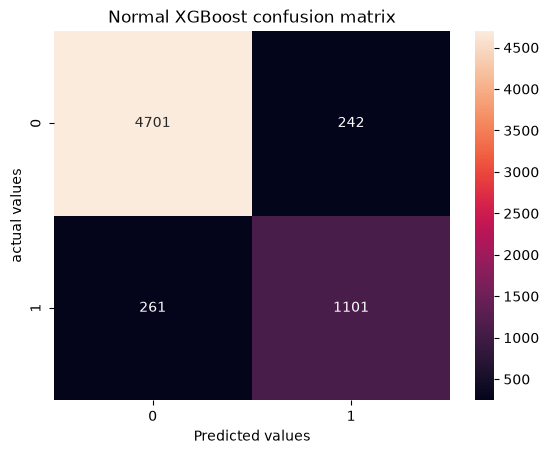

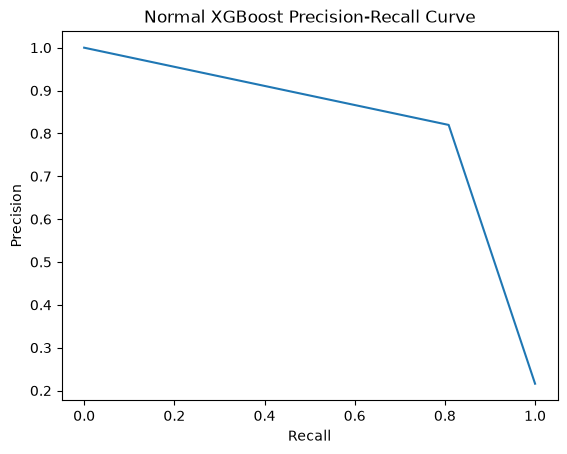

In [45]:
evaluate_model("Normal XGBoost",xg_model,X_test,y_test)

In [59]:
#get the prob. of class 1 from XGBoost

prob = xg_model.predict_proba(X_test)[:,1]
prob

# for each threshold calculate precision and recall
precisions,recalls,thresholds = precision_recall_curve(y_test,prob)

#calculate f1 score for each threshold 
f1_scores = []

for i in range(len(thresholds)):
    f1 = (2*precisions[i]*recalls[i])/(precisions[i]+recalls[i]+1e-9)
    f1_scores.append(f1)
    
max_threshold_index = np.argmax(f1_scores)
max_threshold = thresholds[max_threshold_index]
max_f1 = f1_scores[max_threshold_index]

print(f"max threshold is {max_threshold:.4f} and max f1 score is {max_f1:.4f}")

max threshold is 0.6479 and max f1 score is 0.8400


accuracy : 0.94
precision : 0.94
recall : 0.76
f1_score : 0.84
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      4943
           1       0.94      0.76      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.94      0.87      0.90      6305
weighted avg       0.94      0.94      0.93      6305



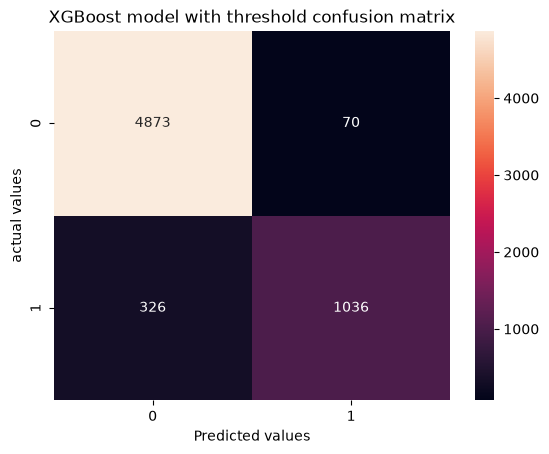

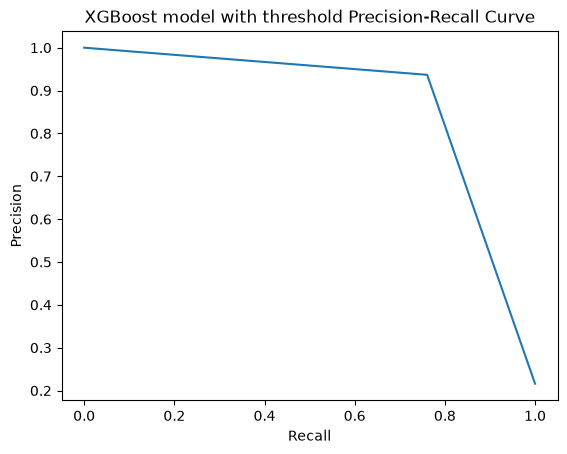

In [60]:
evaluate_model("XGBoost model with threshold",xg_model,X_test,y_test,max_threshold)

In [64]:
def final_model_evaluation(model_name,model,X_test,y_test,threshold=None):
    y_pred_prob = model.predict_proba(X_test)[:,1]
        
    if threshold :
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(X_test)
    
    #metrics  
    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    recall = recall_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    
    print(f"****************{model_name}************")
    print(f"accuracy : {accuracy:.2f}")
    print(f"precision : {precision:.2f}")
    print(f"recall : {recall:.2f}")
    print(f"f1_score : {f1:.2f}")
        
    # cm = confusion_matrix(y_test,y_pred)
    # class_report = classification_report(y_test,y_pred)
    # print(class_report)
    
    # sns.heatmap(cm,annot=True,fmt="d")
    # plt.title(f"{model_name} confusion matrix")
    # plt.ylabel("actual values")
    # plt.xlabel("Predicted values")
    # plt.show()
        

In [65]:
final_model_evaluation("Simple XGBoost", xg_model, X_test, y_test)

final_model_evaluation("Tuned XGBoost", best_sgb, X_test, y_test)

final_model_evaluation("Threshold-Tuned XGBoost", xg_model, X_test, y_test,max_threshold)

****************Simple XGBoost************
accuracy : 0.92
precision : 0.82
recall : 0.81
f1_score : 0.81
****************Tuned XGBoost************
accuracy : 0.92
precision : 0.82
recall : 0.81
f1_score : 0.81
****************Threshold-Tuned XGBoost************
accuracy : 0.94
precision : 0.94
recall : 0.76
f1_score : 0.84


In [66]:
# model calibration (XGBoost model)
from sklearn.calibration import CalibratedClassifierCV,calibration_curve

calibrated_model = CalibratedClassifierCV(
    xg_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train,y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","Pipeline(step...=None, ...))])"
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...00167CF27B790>, <

In [67]:
uncalibrated = xg_model.predict_proba(X_test)[:,1]

calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [68]:
actual_uncal,predicted_uncal = calibration_curve(y_test,uncalibrated,n_bins=10)

In [69]:
actual_uncal

array([0.01127668, 0.04363313, 0.11093991, 0.15048544, 0.16949153,
       0.2459893 , 0.44827586, 0.39285714, 0.77966102, 0.99371069])

In [70]:
predicted_uncal

array([0.03492222, 0.14543695, 0.24629181, 0.3437659 , 0.44630924,
       0.54816444, 0.64264076, 0.73961336, 0.85440683, 0.98571257])

In [71]:
acutal_cal,predicted_cal = calibration_curve(y_test,calibrated,n_bins=10)

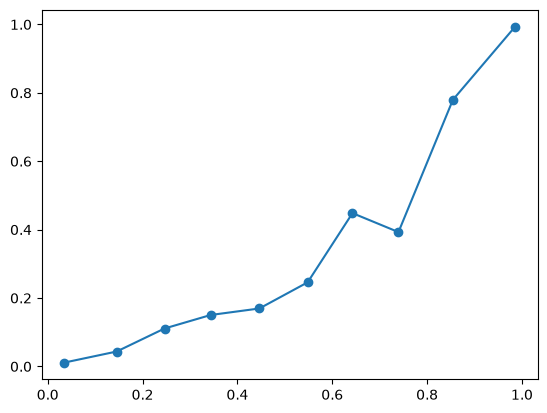

In [72]:
plt.plot(predicted_uncal,actual_uncal,"-o",label="uncalibrated")

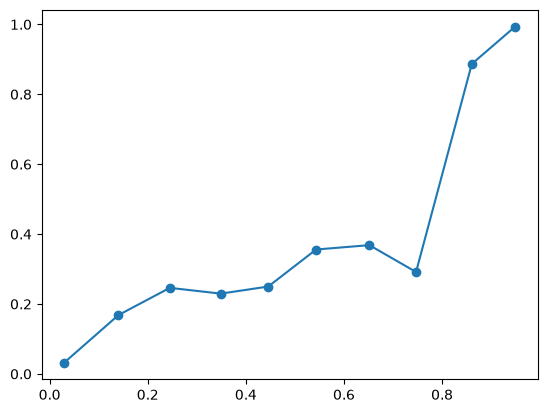

In [73]:
plt.plot(predicted_cal,acutal_cal,"-o",label="calibrated")

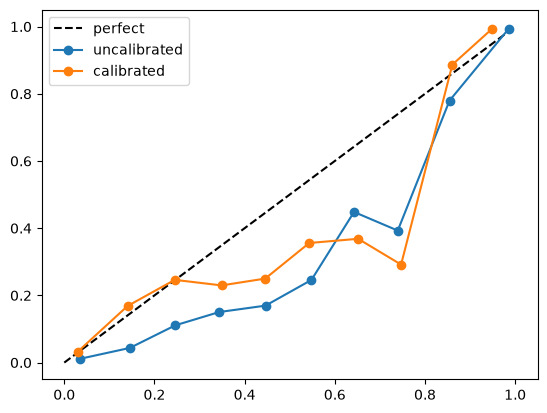

In [ ]:
plt.plot([0,1],[0,1],"k--",label="perfect")
plt.plot(predicted_uncal,actual_uncal,"o-",label="uncalibrated")
plt.plot(predicted_cal,acutal_cal,"o-",label="calibrated")
plt.legend()

# in the graph we see that calibrated line is more close to perfect line.
# hence we will choose the calibrated model

In [90]:
import shap

#STEPS : 
# 1) get the xgb model : we will use the hyperparameter tuned xgb model
xgb_classifier = best_sgb.named_steps["classifier"]
xgb_classifier

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,np.float64(0.6062321432664501)
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [93]:
# 2) transform X_test using the same preprocessing used for training

X_test_processed = best_sgb.named_steps["preprocessor"].transform(X_test)

In [92]:
# 3) get the features names out 
feature_names = best_sgb.named_steps["preprocessor"].get_feature_names_out()

In [94]:
# 4) convert to a dataframe for cleaner SHAP plot

X_test_df = pd.DataFrame(X_test_processed,columns=feature_names)

In [ ]:
# 5) Create SHAP explainer for model
explainer = shap.TreeExplainer(xgb_classifier)

In [100]:
#6 calcuate SHAP values for every row in the test set

shap_values = explainer.shap_values(X_test_df)

shap_values

array([[-1.32067606e-01, -1.19020015e-01,  4.27660614e-01, ...,
        -6.51019625e-03,  1.01307184e-02,  1.53578380e-02],
       [-8.42405185e-02, -1.41730356e+00, -6.26422316e-02, ...,
        -1.29245510e-02,  3.97015084e-03, -1.54719036e-03],
       [ 1.15454532e-01,  4.82625675e+00,  5.97548373e-02, ...,
        -7.36089377e-03,  3.11077456e-05,  1.62726901e-02],
       ...,
       [ 2.71038134e-02,  9.14262116e-01,  5.85938022e-02, ...,
        -8.09191354e-03, -2.92976084e-03,  3.82297486e-03],
       [-1.36792153e-01, -1.28890872e+00,  2.81915188e-01, ...,
        -8.80358275e-03, -8.85414239e-03, -8.25865101e-03],
       [-3.11827838e-01, -1.37811255e+00,  9.36634690e-02, ...,
        -8.64743069e-03,  2.22136825e-02, -1.08046515e-04]],
      shape=(6305, 26), dtype=float32)

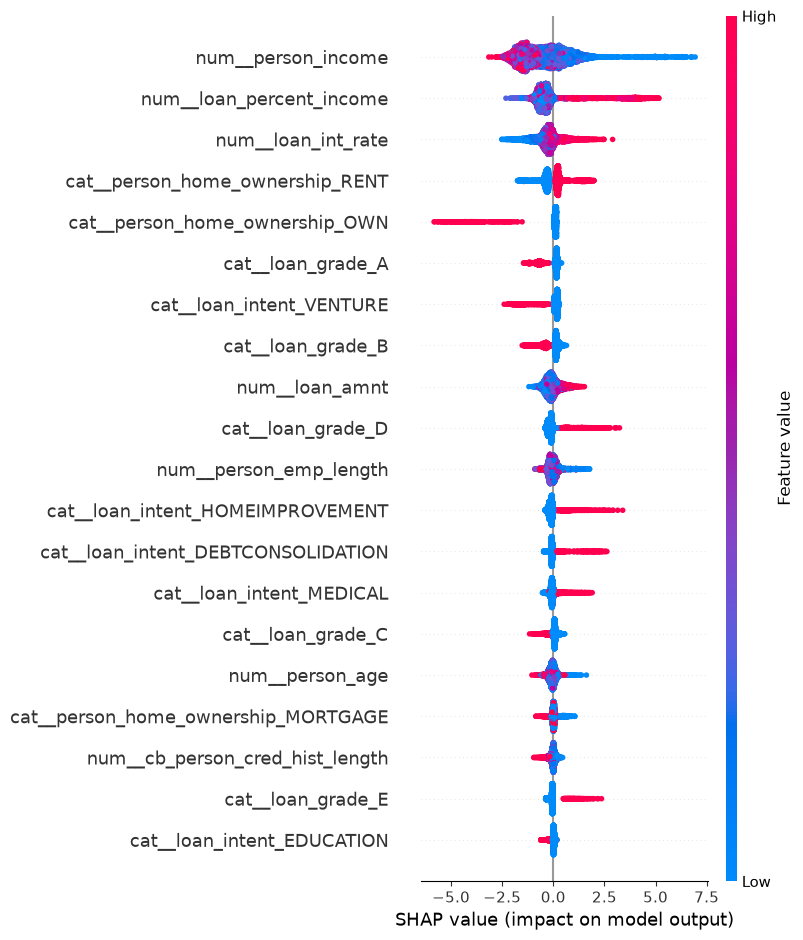

In [101]:
# global explanation
shap.summary_plot(shap_values,X_test_df)

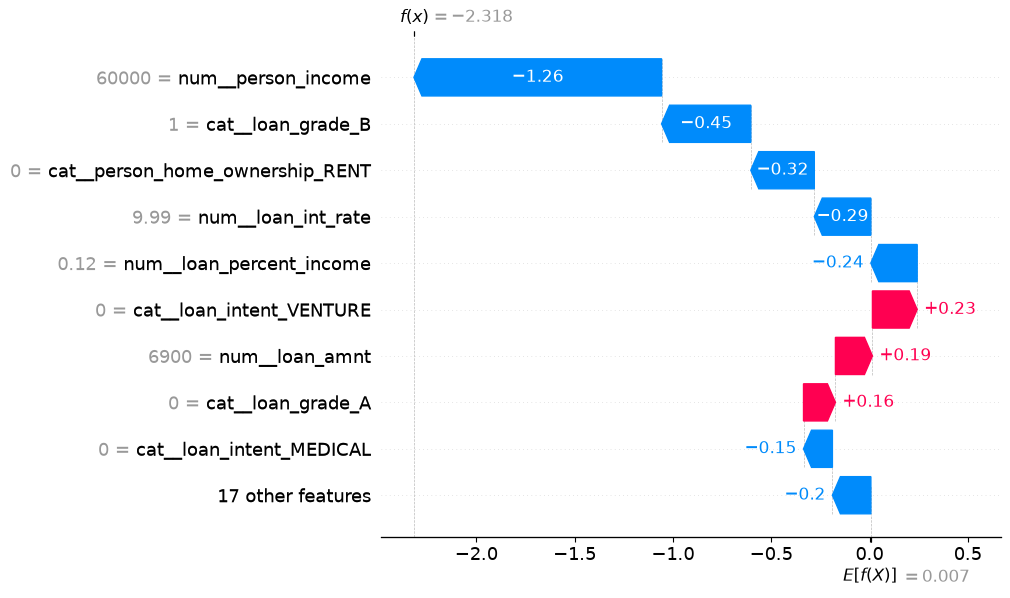

In [102]:
# local explanation
# 1. pick one row for which we need explanation

row_index = 5

#2. draw a waterfall plot showing how each feature pushed the prediction up or down 

shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,  # what was the model's prediction for this applicant
        data = X_test_df.iloc[row_index]
    )
)

In [103]:
# analyzing false positives and false negatives

# get predictions from the best performing XGBoost model on the test set

y_pred = best_sgb.predict(X_test)

result_df = X_test.copy()

result_df["actual"] = y_test

result_df["predicted"] = y_pred



In [104]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [ ]:
# identify false positives : model predicted 1,but actual was 0

false_positive = result_df[(result_df["actual"]==0) & (result_df["predicted"]==1)]

false_positive

# identify false negatives : model predicted 0,but actual was 1

false_negative = result_df[(result_df["actual"]==1) & (result_df["predicted"]==0)]

false_negative

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
8642,23,53950,MORTGAGE,8.0,EDUCATION,E,15000,16.63,0.28,Y,2,1,0
5615,23,39325,MORTGAGE,3.0,EDUCATION,C,2800,12.87,0.07,N,4,1,0
23959,35,62000,MORTGAGE,9.0,HOMEIMPROVEMENT,B,13000,9.25,0.21,N,10,1,0
4305,23,52000,RENT,5.0,PERSONAL,D,4600,14.96,0.09,N,2,1,0
2584,25,29000,RENT,9.0,MEDICAL,A,3000,6.62,0.10,N,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10520,26,52703,MORTGAGE,5.0,MEDICAL,B,4000,11.89,0.06,N,4,1,0
19389,34,30857,RENT,6.0,VENTURE,C,3000,13.06,0.10,N,9,1,0
4105,22,22560,RENT,3.0,PERSONAL,D,4200,15.20,0.19,Y,4,1,0
22836,27,52600,MORTGAGE,2.0,PERSONAL,D,21600,17.27,0.41,N,9,1,0


In [112]:
print(f"false positives : {len(false_positive)}")
print(f"false negative : {len(false_negative)}")

false positives : 249
false negative : 262


In [115]:
# save the model


# now at the end we will be using the hyperparameter tuned xg model. But we will do calibration of it and then save it and use it in deployement

calibrated_hyper_xg_model = CalibratedClassifierCV(
    best_sgb,
    method="sigmoid",
    cv=5
)

calibrated_hyper_xg_model.fit(X_train,y_train)

final_model_evaluation("Hyper parameter tuned XGB model with calibration",calibrated_hyper_xg_model,X_test,y_test)



****************Hyper parameter tuned XGB model with calibration************
accuracy : 0.93
precision : 0.92
recall : 0.77
f1_score : 0.84


In [119]:
import joblib

joblib.dump(calibrated_hyper_xg_model,"credit_risk_model.pkl")

# we also want to save the best threshold value claculated before but that was calcuated using the base xg_model. So we will first calculate the threshold for this calibrated hyperparameter tuned xg model

prob = calibrated_hyper_xg_model.predict_proba(X_test)[:,1]

precisions,recalls,thresholds = precision_recall_curve(y_test,prob)

f1_scores = []

for i in range(len(thresholds)):
    f1_score = (2*precisions[i]*recalls[i])/(precisions[i]+recalls[i]+1e-9)
    f1_scores.append(f1_score)


max_f1_score_index = np.argmax(f1_scores)
max_f1_score = f1_scores[max_f1_score_index]
max_threshold = thresholds[max_f1_score_index]

print(f"max threshold is {max_threshold} and max f1 score is {max_f1_score}")

joblib.dump(max_threshold,"best_threshold.pkl")


max threshold is 0.7477484801221584 and max f1 score is 0.8395475487349346


['best_threshold.pkl']

In [ ]:
max_threshold

np.float32(0.6478967)